# **Data Preprocessing & Machine learning**

<img src="https://thumb.wikimedia.org/wikipedia/commons/thumb/f/fd/RMS_Titanic_3.jpg/1920px-RMS_Titanic_3.jpg?utm_source=ko.wikipedia.org&utm_campaign=index&utm_content=thumbnail">

## **0. Introduction**

- 탐색적 데이터 분석(Exploratory Data Analysis)과 피처 엔지니어링(Feature Engineering)에 초점을 맞춘 입문자 수준의 가이드

- 피처 엔지니어링에 도메인 지식을 적용

- 탐색적 데이터 분석(Exploratory Data Analysis), 피처 엔지니어링(Feature Engineering), 그리고 모델(Model)이라는 3가지 주요 섹션으로 구성하여 완성하라

In [1]:
# @title 관련 모듈 호출
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="darkgrid")

from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, StandardScaler
from sklearn.metrics import roc_curve, auc
from sklearn.model_selection import StratifiedKFold

import string
import warnings
warnings.filterwarnings('ignore')

SEED = 42

* Training set has **891** rows and test set has **418** rows
* Training set have **12** features and test set have **11** features
* One extra feature in training set is `Survived` feature, which is the target variable

In [2]:
path = 'https://github.com/wesm/pydata-book/blob/3rd-edition/datasets/titanic/'
f'{path}train.csv'

'https://github.com/wesm/pydata-book/blob/3rd-edition/datasets/titanic/train.csv'

In [5]:
raw_path = 'https://raw.githubusercontent.com/wesm/pydata-book/3rd-edition/datasets/titanic/'
df_train = pd.read_csv(f'{raw_path}train.csv')
df_test = pd.read_csv(f'{raw_path}test.csv')
df_all = pd.concat([df_train, df_test], sort=True).reset_index(drop=True)
df_all

,Age,Cabin,Embarked,Fare,Name,Parch,PassengerId,Pclass,Sex,SibSp,Survived,Ticket
0,22.0,NaN,S,7.2500,"Braund, Mr. Owen Harris",0,1,3,male,1,0.0,A/5 21171
1,38.0,C85,C,71.2833,"Cumings, Mrs. John Bradley (Florence Briggs Th...",0,2,1,female,1,1.0,PC 17599
2,26.0,NaN,S,7.9250,"Heikkinen, Miss. Laina",0,3,3,female,0,1.0,STON/O2. 3101282
3,35.0,C123,S,53.1000,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",0,4,1,female,1,1.0,113803
4,35.0,NaN,S,8.0500,"Allen, Mr. William Henry",0,5,3,male,0,0.0,373450
...,...,...,...,...,...,...,...,...,...,...,...,...
1304,NaN,NaN,S,8.0500,"Spector, Mr. Woolf",0,1305,3,male,0,NaN,A.5. 3236
1305,39.0,C105,C,108.9000,"Oliva y Ocana, Dona. Fermina",0,1306,1,female,0,NaN,PC 17758
1306,38.5,NaN,S,7.2500,"Saether, Mr. Simon Sivertsen",0,1307,3,male,0,NaN,SOTON/O.Q. 3101262
1307,NaN,NaN,S,8.0500,"Ware, Mr. Frederick",0,1308,3,male,0,NaN,359309


In [4]:
print(f'Number of Training Examples = {df_train.shape[0]}')
print(f'Number of Test Examples = {df_test.shape[0]}\n')
print(f'Training X Shape = {df_train.shape}')
print(f"Training y Shape = {df_train['Survived'].shape[0]}\n")
print(f'Test X Shape = {df_test.shape}')
print(f'Test y Shape = {df_test.shape[0]}\n')
print(f'df_train(훈련데이터) 컬럼 명 : {df_train.columns}\n')
print(f'df_test(검증데이터) 컬럼 명 : {df_test.columns}')

Number of Training Examples = 891
Number of Test Examples = 418

Training X Shape = (891, 12)
Training y Shape = 891

Test X Shape = (418, 11)
Test y Shape = 418

df_train(훈련데이터) 컬럼 명 : Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')

df_test(검증데이터) 컬럼 명 : Index(['PassengerId', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch',
       'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='object')


## **1. Exploratory Data Analysis**

### **1.1 Overview**
* `PassengerId` is the unique id of the row and it doesn't have any effect on target
* `Survived` is the target variable we are trying to predict (**0** or **1**):
    - **1 = Survived**
    - **0 = Not Survived**
* `Pclass` (Passenger Class) is the socio-economic status of the passenger and it is a categorical ordinal feature which has **3** unique values (**1**,  **2 **or **3**):
    - **1 = Upper Class**
    - **2 = Middle Class**
    - **3 = Lower Class**
* `Name`, `Sex` and `Age` are self-explanatory
* `SibSp` is the total number of the passengers' siblings and spouse
* `Parch` is the total number of the passengers' parents and children
* `Ticket` is the ticket number of the passenger
* `Fare` is the passenger fare
* `Cabin` is the cabin number of the passenger
* `Embarked` is port of embarkation and it is a categorical feature which has **3** unique values (**C**, **Q** or **S**):
    - **C = Cherbourg**
    - **Q = Queenstown**
    - **S = Southampton**

In [6]:
def summarize(df: pd.DataFrame) -> pd.DataFrame:
    return pd.DataFrame([
        {
            'Column': col,
            'N_Unique': df[col].nunique(),
            'Dtype': df[col].dtype,
            'Null_Count': df[col].isna().sum(),
            'Null_Ratio(%)': round(df[col].isna().mean() * 100, 2),
            'Sample_Values': df[col].dropna().unique()[:7].tolist()
        }
        for col in df.columns
    ])

In [7]:
summarize(df_train)

,Column,N_Unique,Dtype,Null_Count,Null_Ratio(%),Sample_Values
0,PassengerId,891,int64,0,0.00,"[1, 2, 3, 4, 5, 6, 7]"
1,Survived,2,int64,0,0.00,"[0, 1]"
2,Pclass,3,int64,0,0.00,"[3, 1, 2]"
3,Name,891,object,0,0.00,"[Braund, Mr. Owen Harris, Cumings, Mrs. John B..."
4,Sex,2,object,0,0.00,"[male, female]"
5,Age,88,float64,177,19.87,"[22.0, 38.0, 26.0, 35.0, 54.0, 2.0, 27.0]"
6,SibSp,7,int64,0,0.00,"[1, 0, 3, 4, 2, 5, 8]"
7,Parch,7,int64,0,0.00,"[0, 1, 2, 5, 3, 4, 6]"
8,Ticket,681,object,0,0.00,"[A/5 21171, PC 17599, STON/O2. 3101282, 113803..."
9,Fare,248,float64,0,0.00,"[7.25, 71.2833, 7.925, 53.1, 8.05, 8.4583, 51...."


In [8]:
summarize(df_test)

,Column,N_Unique,Dtype,Null_Count,Null_Ratio(%),Sample_Values
0,PassengerId,418,int64,0,0.00,"[892, 893, 894, 895, 896, 897, 898]"
1,Pclass,3,int64,0,0.00,"[3, 2, 1]"
2,Name,418,object,0,0.00,"[Kelly, Mr. James, Wilkes, Mrs. James (Ellen N..."
3,Sex,2,object,0,0.00,"[male, female]"
4,Age,79,float64,86,20.57,"[34.5, 47.0, 62.0, 27.0, 22.0, 14.0, 30.0]"
5,SibSp,7,int64,0,0.00,"[0, 1, 2, 3, 4, 5, 8]"
6,Parch,8,int64,0,0.00,"[0, 1, 3, 2, 4, 6, 5]"
7,Ticket,363,object,0,0.00,"[330911, 363272, 240276, 315154, 3101298, 7538..."
8,Fare,169,float64,1,0.24,"[7.8292, 7.0, 9.6875, 8.6625, 12.2875, 9.225, ..."
9,Cabin,76,object,327,78.23,"[B45, E31, B57 B59 B63 B66, B36, A21, C78, D34]"


### **1.2 Missing Values**
As seen from below, some columns have missing values. `display_missing` function shows the count of missing values in every column in both training and test set.
* Training set have missing values in `Age`, `Cabin` and `Embarked` columns
* Test set have missing values in `Age`, `Cabin` and `Fare` columns

It is convenient to work on concatenated training and test set while dealing with missing values, otherwise filled data may overfit to training or test set samples. The count of missing values in `Age`, `Embarked` and `Fare` are smaller compared to total sample, but roughly **80%** of the `Cabin` is missing. Missing values in `Age`, `Embarked` and `Fare` can be filled with descriptive statistical measures but that wouldn't work for `Cabin`.


## 1. 결측치 현황 (Missing Values)

`display_missing()` 함수의 실행 결과, 학습 데이터와 테스트 데이터에서 다음과 같은 결측치가 확인되었다.

- **학습 데이터 (Training Set)**
  - `Age`, `Cabin`, `Embarked` 컬럼에 결측치 존재
- **테스트 데이터 (Test Set)**
  - `Age`, `Cabin`, `Fare` 컬럼에 결측치 존재

## 2. 결측치 처리 전략 (Missing Value Imputation Strategy)

### ① 데이터 병합 처리 (Data Concatenation)

- 학습 데이터(Training Set)와 테스트 데이터(Test Set)를 `pd.concat()`으로 병합하여 결측치를 통합적으로 처리한다.
- 두 데이터셋에 동일한 결측치 처리 기준을 적용할 수 있다는 장점이 있다.
- 단, 테스트 데이터의 정보를 활용하는 것이므로 데이터 누수(Data Leakage) 가능성을 고려해야 한다. 특히 타깃 변수(`Survived`)는 결측치 처리에 활용하지 않는다.

### ② Age, Embarked, Fare 컬럼

- 결측치 비율이 상대적으로 낮으므로 기술 통계량(Descriptive Statistics)을 활용하여 대체할 수 있다.
- `Age`: 중앙값(Median) 또는 평균(Mean)으로 대체
- `Embarked`: 최빈값(Mode)으로 대체
- `Fare`: 중앙값(Median)으로 대체

### ③ Cabin 컬럼

- 전체 데이터의 약 80%가 결측치이므로 평균, 중앙값, 최빈값과 같은 단순 통계량으로 대체하기 어렵다.
- 다음과 같은 별도의 처리 전략을 고려할 수 있다.
  - 결측 여부를 나타내는 새로운 변수 생성 (`Cabin_missing`)
  - 객실 정보가 존재하는 경우와 그렇지 않은 경우를 구분
  - 객실 번호에서 갑판(Deck) 정보를 추출하여 새로운 변수로 활용
  - 분석 목적에 따라 원본 `Cabin` 컬럼 제거


#### **1.2.1 Age**
Missing values in `Age` are filled with median age, but using median age of the whole data set is not a good choice. Median age of `Pclass` groups is the best choice because of its high correlation with `Age` **(0.408106)** and `Survived` **(0.338481)**. It is also more logical to group ages by passenger classes instead of other features.

In order to be more accurate, `Sex` feature is used as the second level of `groupby` while filling the missing `Age` values. As seen from below, `Pclass` and `Sex` groups have distinct median `Age` values. When passenger class increases, the median age for both males and females also increases. However, females tend to have slightly lower median `Age` than males. The median ages below are used for filling the missing values in `Age` feature.


### ④ Age 결측치 대체 (Age Imputation by Pclass and Sex)

- `Age` 결측치를 보다 정확하게 대체하기 위해 `Pclass`와 `Sex`를 기준으로 그룹화(`groupby`)하여 중앙값(Median)을 계산한다.
- 승객 등급(`Pclass`)과 성별(`Sex`)에 따라 연령 중앙값에 차이가 나타난다.
- 승객 등급이 높아질수록 남성과 여성 모두 연령 중앙값이 증가하는 경향이 있다.
- 여성의 연령 중앙값은 남성보다 다소 낮게 나타난다.
- 따라서 `Pclass`와 `Sex` 조합별로 계산한 연령 중앙값을 해당 그룹의 결측치 대체값으로 사용한다.


#### **1.2.2 Embarked**
`Embarked` is a categorical feature and there are only **2** missing values in whole data set. Both of those passengers are female, upper class and they have the same ticket number. This means that they know each other and embarked from the same port together. The mode `Embarked` value for an upper class female passenger is **C (Cherbourg)**, but this doesn't necessarily mean that they embarked from that port.


### ⑤ Embarked 결측치 대체 (Embarked Imputation)

- `Embarked`는 범주형(Categorical) 변수이며, 전체 데이터에서 결측치는 단 2개이다.
- 두 승객은 모두 여성이고, 상위 등급(`Pclass`)에 속하며 동일한 티켓 번호를 가지고 있다.
- 따라서 두 승객은 서로 알고 지내며 동일한 항구에서 함께 승선했을 가능성이 있다.
- 상위 등급 여성 승객의 `Embarked` 최빈값(Mode)은 **C(Cherbourg)** 로 나타난다.
- 다만, 최빈값이 반드시 실제 승선 항구를 의미하는 것은 아니므로 추정에 따른 대체값으로 활용한다.

When I googled **Stone, Mrs. George Nelson (Martha Evelyn)**, I found that she embarked from **S (Southampton)** with her maid **Amelie Icard**, in this page [Martha Evelyn Stone: Titanic Survivor](https://www.encyclopedia-titanica.org/titanic-survivor/martha-evelyn-stone.html).

> *Mrs Stone boarded the Titanic in Southampton on 10 April 1912 and was travelling in first class with her maid Amelie Icard. She occupied cabin B-28.*

Missing values in `Embarked` are filled with **S** with this information.


### ⑥ Embarked 결측치 대체 근거 (Evidence-based Imputation)

- 승객 **Stone, Mrs. George Nelson (Martha Evelyn)**에 대한 추가 정보를 검색한 결과, 해당 승객은 1912년 4월 10일 사우샘프턴(Southampton)에서 타이타닉호에 승선한 것으로 확인되었다.
- 당시 1등석(First Class)을 이용했으며, 하녀인 **Amelie Icard**와 함께 여행했다.
- 이용한 객실은 **B-28**이었다.
- 이러한 외부 자료를 근거로 해당 승객의 `Embarked` 결측치를 **S(Southampton)** 로 대체한다.

#### **1.2.3 Fare**
There is only one passenger with missing `Fare` value. We can assume that `Fare` is related to family size (`Parch` and `SibSp`) and `Pclass` features. Median `Fare` value of a male with a third class ticket and no family is a logical choice to fill the missing value.


### ⑦ Fare 결측치 대체 (Fare Imputation)

- `Fare` 결측치는 전체 데이터에서 단 1개만 존재한다.
- 요금(`Fare`)은 가족 구성원 수(`Parch`, `SibSp`)와 승객 등급(`Pclass`)에 영향을 받을 수 있다.
- 해당 승객은 3등석(`Pclass = 3`) 남성이며, 동반 가족이 없는 것으로 확인된다.
- 따라서 **가족이 없는 3등석 남성 승객의 요금 중앙값(Median Fare)** 을 결측치 대체값으로 사용하는 것이 합리적이다.

#### **1.2.4 Cabin**
`Cabin` feature is little bit tricky and it needs further exploration. The large portion of the `Cabin` feature is missing and the feature itself can't be ignored completely because some the cabins might have higher survival rates. It turns out to be the first letter of the `Cabin` values are the decks in which the cabins are located. Those decks were mainly separated for one passenger class, but some of them were used by multiple passenger classes.
![alt text](https://vignette.wikia.nocookie.net/titanic/images/f/f9/Titanic_side_plan.png/revision/latest?cb=20180322183733)
* On the Boat Deck there were **6** rooms labeled as **T, U, W, X, Y, Z** but only the **T** cabin is present in the dataset
* **A**, **B** and **C** decks were only for 1st class passengers
* **D** and **E** decks were for all classes
* **F** and **G** decks were for both 2nd and 3rd class passengers
* From going **A** to **G**, distance to the staircase increases which might be a factor of survival

In [ ]:
# @title **Cabin 컬럼 제거하고(결측치가 너무 많음)**

### **1.3 Target Distribution**
* **38.38%** (342/891) of training set is **Class 1**
* **61.62%** (549/891) of training set is **Class 0**

### **1.4 Correlations**
Features are highly correlated with each other and dependent to each other. The highest correlation between features is **0.549500** in training set and **0.577147** in test set (between `Fare` and `Pclass`). The other features are also highly correlated. There are **9** correlations in training set and **6** correlations in test set that are higher than **0.1**.


### ⑩ 변수 간 상관관계 분석 (Feature Correlation Analysis)

- 각 변수는 서로 높은 상관관계를 가지며, 변수 간 상호 의존성이 존재한다.
- 변수 간 가장 높은 상관계수는 다음과 같다.
  - **학습 데이터(Training Set):** 0.549500
  - **테스트 데이터(Test Set):** 0.577147
  - 두 데이터셋 모두 `Fare`와 `Pclass` 사이에서 가장 높은 상관관계가 나타났다.
- 상관계수가 0.1을 초과하는 변수 쌍은 다음과 같다.
  - 학습 데이터: 9개
  - 테스트 데이터: 6개
- 따라서 변수 간 상관관계를 고려하여 특성(Feature)을 분석하고, 모델 학습 시 다중공선성(Multicollinearity) 가능성을 검토할 필요가 있다.

### **1.5 Target Distribution in Features**

#### **1.5.1 Continuous Features**
Both of the continuous features (`Age` and `Fare`) have good split points and spikes for a decision tree to learn. One potential problem for both features is, the distribution has more spikes and bumps in training set, but it is smoother in test set. Model may not be able to generalize to test set because of this reason.

* Distribution of `Age` feature clearly shows that children younger than 15 has a higher survival rate than any of the other age groups
* In distribution of `Fare` feature, the survival rate is higher on distribution tails. The distribution also has positive skew because of the extremely large outliers

#### **1.5.2 Categorical Features**
Every categorical feature has at least one class with high mortality rate. Those classes are very helpful to predict whether the passenger is a survivor or victim. Best categorical features are `Pclass` and `Sex` because they have the most homogenous distributions.

* Passengers boarded from **Southampton** has a lower survival rate unlike other ports. More than half of the passengers boarded from **Cherbourg** had survived. This observation could be related to `Pclass` feature
* `Parch` and `SibSp` features show that passengers with only one family member has a higher survival rate

### **1.6 Conclusion**
Most of the features are correlated with each other. This relationship can be used to create new features with feature transformation and feature interaction. Target encoding could be very useful as well because of the high correlations with `Survived` feature.

Split points and spikes are visible in continuous features. They can be captured easily with a decision tree model, but linear models may not be able to spot them.

Categorical features have very distinct distributions with different survival rates. Those features can be one-hot encoded. Some of those features may be combined with each other to make new features.

Created a new feature called `Deck` and dropped `Cabin` feature at the **Exploratory Data Analysis** part.

1. 특성 간 상관관계 활용
> - 변수 간 높은 상관관계를 이용하여 특성 변환(Feature Transformation) 및 특성 조합(Feature Interaction)을 통해 새로운 변수를 생성한다.
> - Survived와 상관관계가 높은 변수에는 타깃 인코딩(Target Encoding)을 적용할 수 있다.
2. 연속형 변수의 비선형 패턴
> - 연속형 변수에서 특정 분기점(Split Points)과 급격한 변화(Spikes)가 관찰된다.
> - 의사결정나무(Decision Tree)는 이러한 패턴을 잘 포착하지만, 선형 모델(Linear Model)은 포착하기 어려울 수 있다.
> - 선형 모델에서도 이러한 분기점과 스파이크를 잡아내게 하려면, 연속형 변수(Age, Fare)를 그대로 넣지 않고 그래프의 분기점을 기준으로 구간을 나누는 구간화(Binning, 예: pd.cut / pd.qcut)를 적용해 범주형 피처로 변환해 주면 됩니다.
3. 범주형 변수의 인코딩 및 조합
> - 생존율 차이가 뚜렷한 범주형 변수는 원-핫 인코딩(One-Hot Encoding)을 적용한다.
> - 관련 범주형 변수들을 결합하여 새로운 특성을 생성할 수 있다.

## **2. Feature Engineering**

### **2.1 Binning Continuous Features**

#### **2.1.1 Fare**
`Fare` feature is positively skewed and survival rate is extremely high on the right end. **13** quantile based bins are used for `Fare` feature. Even though the bins are too much, they provide decent amount of information gain. The groups at the left side of the graph has the lowest survival rate and the groups at the right side of the graph has the highest survival rate. This high survival rate was not visible in the distribution graph. There is also an unusual group **(15.742, 23.25]** in the middle with high survival rate that is captured in this process.

#### **2.1.2 Age**
`Age` feature has a normal distribution with some spikes and bumps and **10** quantile based bins are used for `Age`. The first bin has the highest survival rate and 4th bin has the lowest survival rate. Those were the biggest spikes in the distribution. There is also an unusual group **(34.0, 40.0]** with high survival rate that is captured in this process.

### **2.2 Frequency Encoding**
`Family_Size` is created by adding `SibSp`, `Parch` and **1**. `SibSp` is the count of siblings and spouse, and `Parch` is the count of parents and children. Those columns are added in order to find the total size of families. Adding **1** at the end, is the current passenger. Graphs have clearly shown that family size is a predictor of survival because different values have different survival rates.
* Family Size with **1** are labeled as **Alone**
* Family Size with **2**, **3** and **4** are labeled as **Small**
* Family Size with **5** and **6** are labeled as **Medium**
* Family Size with **7**, **8** and **11** are labeled as **Large**

### **2.3 Title & Is Married**
`Title` is created by extracting the prefix before `Name` feature. According to graph below, there are many titles that are occuring very few times. Some of those titles doesn't seem correct and they need to be replaced. **Miss**, **Mrs**, **Ms**, **Mlle**, **Lady**, **Mme**, **the Countess**, **Dona** titles are replaced with **Miss/Mrs/Ms** because all of them are female. Values like **Mlle**, **Mme** and **Dona** are actually the name of the passengers, but they are classified as titles because `Name` feature is split by comma. **Dr**, **Col**, **Major**, **Jonkheer**, **Capt**, **Sir**, **Don** and **Rev** titles are replaced with **Dr/Military/Noble/Clergy** because those passengers have similar characteristics. **Master** is a unique title. It is given to male passengers below age **26**. They have the highest survival rate among all males.

`Is_Married` is a binary feature based on the **Mrs** title. **Mrs** title has the highest survival rate among other female titles. This title needs to be a feature because all female titles are grouped with each other.

### **2.4 Target Encoding**
`extract_surname` function is used for extracting surnames of passengers from the `Name` feature. `Family` feature is created with the extracted surname. This is necessary for grouping passengers in the same family.

### **2.5 Feature Transformation**

#### **2.5.1 Label Encoding Non-Numerical Features**
`Embarked`, `Sex`, `Deck` , `Title` and `Family_Size_Grouped` are object type, and `Age` and `Fare` features are category type. They are converted to numerical type with `LabelEncoder`. `LabelEncoder` basically labels the classes from **0** to **n**. This process is necessary for models to learn from those features.

#### **2.5.2 One-Hot Encoding the Categorical Features**
The categorical features (`Pclass`, `Sex`, `Deck`, `Embarked`, `Title`) are converted to one-hot encoded features with `OneHotEncoder`. `Age` and `Fare` features are not converted because they are ordinal unlike the previous ones.

In [9]:
# @title **훈련과 검증(Hold-Out) 데이터 분리**

In [11]:
! pip install mglearn -q

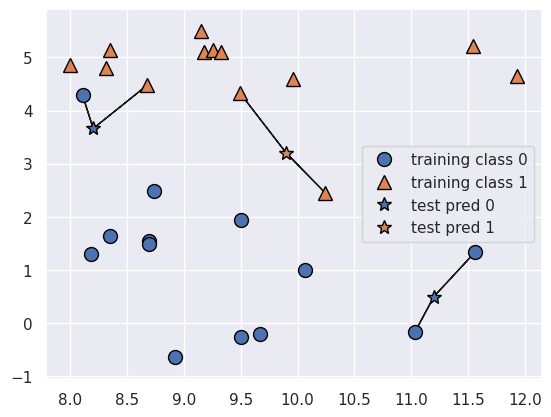

In [17]:
# @title
import mglearn
mglearn.plots.plot_knn_classification(n_neighbors=2)

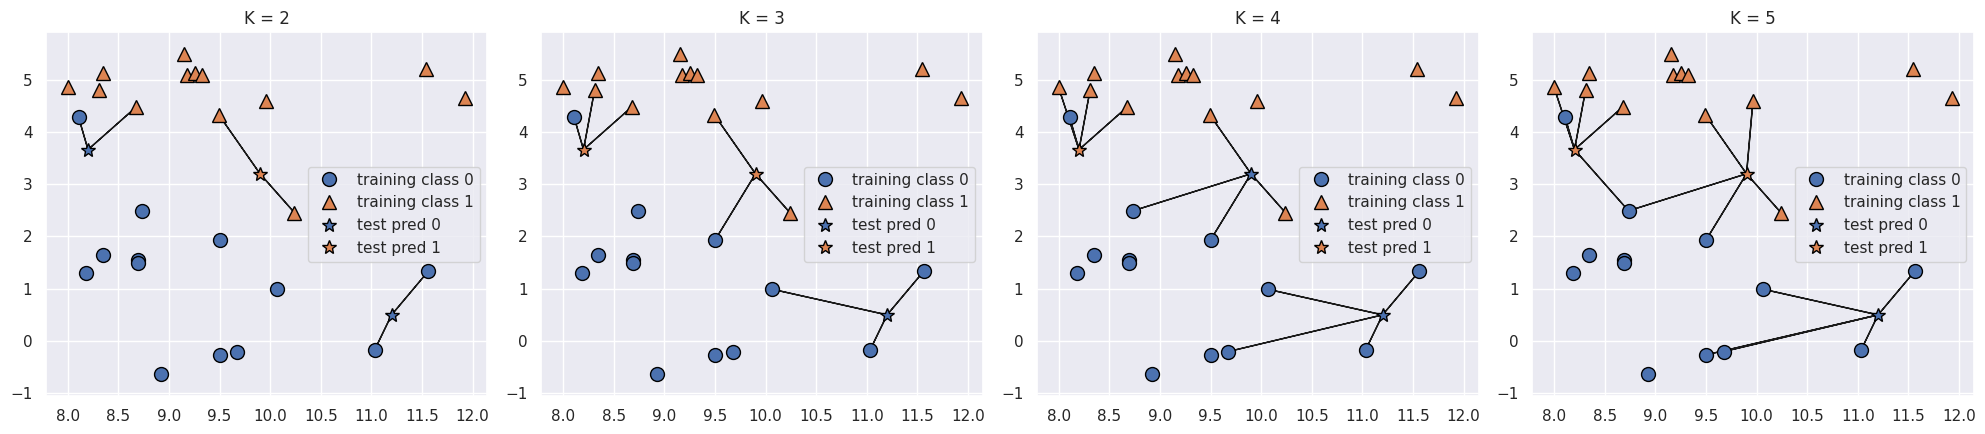

In [19]:
# @title
import matplotlib.pyplot as plt
import mglearn

# 1행 4열 서브플롯 생성 (가로로 길게 배치)
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))

for n, ax in zip([2, 3, 4, 5], axes):
  plt.sca(ax)  # 현재 활성화된 축을 ax로 설정
  mglearn.plots.plot_knn_classification(n_neighbors=n)
  ax.set_title(f"K = {n}")  # 각 그래프 제목 표시

plt.tight_layout()
plt.show()

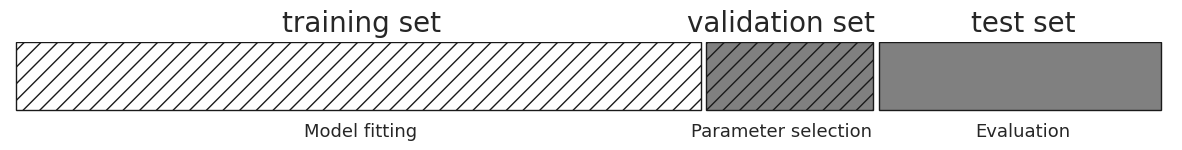

In [23]:
# @title **방법 1. 데이터를 3개로 구분하여 학습(하이퍼파라미터 튜닝)**
mglearn.plots.plot_threefold_split()

In [27]:
# @title
from sklearn.datasets import make_classification
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier

X, y = make_classification(n_samples=500, n_features=4, random_state=42)

# Train/Val/Test = 60/20/20
X_train, X_tmp, y_train, y_tmp = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_tmp, y_tmp, test_size=0.5, random_state=42, stratify=y_tmp)

# (p, k) 격자 탐색
results = []
for p in (1, 2):
    for k in (1, 3, 5, 7, 9):
        model = KNeighborsClassifier(n_neighbors=k, p=p).fit(X_train, y_train)
        acc = round(accuracy_score(y_val, model.predict(X_val)), 4)
        results.append({"p": p, "k": k, "val_acc": acc})
        print(f"p={p} k={k} -> val acc: {acc:.4f}")

# 검증 성능 최고 조합으로 test 평가
best = max(results, key=lambda r: r["val_acc"])
final = KNeighborsClassifier(n_neighbors=best["k"], p=best["p"]).fit(X_train, y_train)
best["test_acc"] = round(accuracy_score(y_test, final.predict(X_test)), 4)

print(f"\n최적: p={best['p']}, k={best['k']} | test acc: {best['test_acc']:.4f}")
print(*results, sep="\n")

p=1 k=1 -> val acc: 0.9700
p=1 k=3 -> val acc: 0.9600
p=1 k=5 -> val acc: 0.9500
p=1 k=7 -> val acc: 0.9300
p=1 k=9 -> val acc: 0.9200
p=2 k=1 -> val acc: 0.9700
p=2 k=3 -> val acc: 0.9600
p=2 k=5 -> val acc: 0.9500
p=2 k=7 -> val acc: 0.9200
p=2 k=9 -> val acc: 0.9200

최적: p=1, k=1 | test acc: 0.9400
{'p': 1, 'k': 1, 'val_acc': 0.97, 'test_acc': 0.94}
{'p': 1, 'k': 3, 'val_acc': 0.96}
{'p': 1, 'k': 5, 'val_acc': 0.95}
{'p': 1, 'k': 7, 'val_acc': 0.93}
{'p': 1, 'k': 9, 'val_acc': 0.92}
{'p': 2, 'k': 1, 'val_acc': 0.97}
{'p': 2, 'k': 3, 'val_acc': 0.96}
{'p': 2, 'k': 5, 'val_acc': 0.95}
{'p': 2, 'k': 7, 'val_acc': 0.92}
{'p': 2, 'k': 9, 'val_acc': 0.92}


In [24]:
# @title **방법 2. 데이터를 2개로 구분하여 교차검증과 학습(하이퍼파라미터 튜닝) & Hold-0out 데이터 검증(test)**

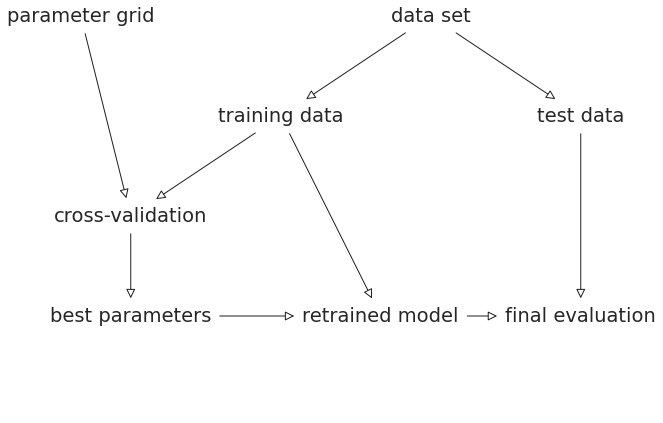

In [21]:
mglearn.plots.plot_grid_search_overview()

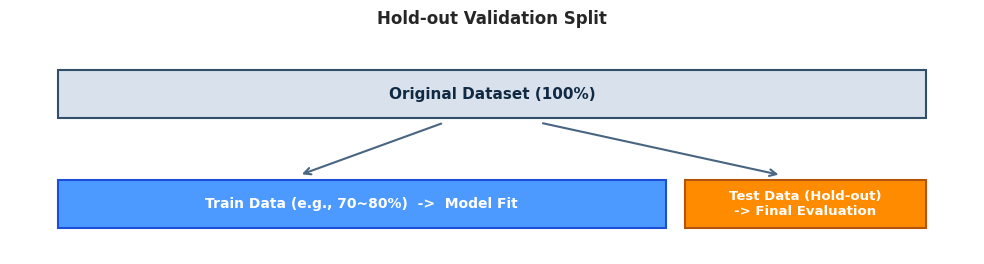

In [20]:
# @title
import matplotlib.pyplot as plt
import matplotlib.patches as patches

fig, ax = plt.subplots(figsize=(10, 2.8))

# 전체 데이터
ax.add_patch(patches.Rectangle((0.05, 0.62), 0.90, 0.22, facecolor="#D9E2EC", edgecolor="#334E68", lw=1.5))
ax.text(0.50, 0.73, "Original Dataset (100%)", ha="center", va="center", fontsize=11, fontweight="bold", color="#102A43")

# 분할 화살표
ax.annotate("", xy=(0.30, 0.36), xytext=(0.45, 0.60), arrowprops=dict(arrowstyle="->", lw=1.5, color="#486581"))
ax.annotate("", xy=(0.80, 0.36), xytext=(0.55, 0.60), arrowprops=dict(arrowstyle="->", lw=1.5, color="#486581"))

# Train Set (예: 70% 또는 80%)
ax.add_patch(patches.Rectangle((0.05, 0.12), 0.63, 0.22, facecolor="#4C9AFF", edgecolor="#1D4ED8", lw=1.5))
ax.text(0.365, 0.23, "Train Data (e.g., 70~80%)  ->  Model Fit", ha="center", va="center", fontsize=10, fontweight="bold", color="white")

# Test Set (Hold-out, 예: 30% 또는 20%)
ax.add_patch(patches.Rectangle((0.70, 0.12), 0.25, 0.22, facecolor="#FF8B00", edgecolor="#B45309", lw=1.5))
ax.text(0.825, 0.23, "Test Data (Hold-out)\n-> Final Evaluation", ha="center", va="center", fontsize=9.5, fontweight="bold", color="white")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")
plt.title("Hold-out Validation Split", fontsize=12, fontweight="bold", pad=8)
plt.tight_layout()
plt.show()

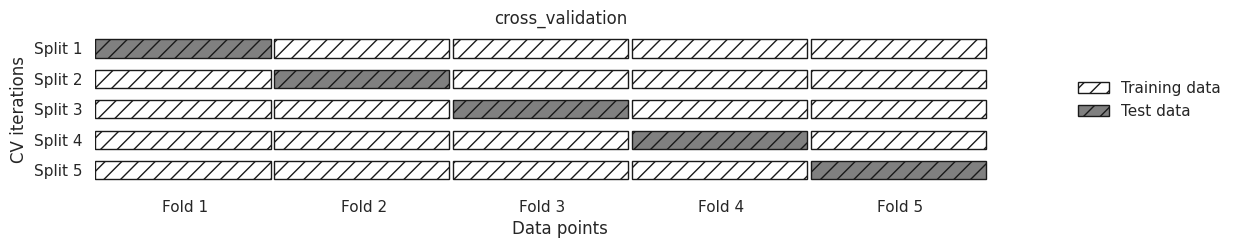

In [16]:
mglearn.plots.plot_cross_validation()

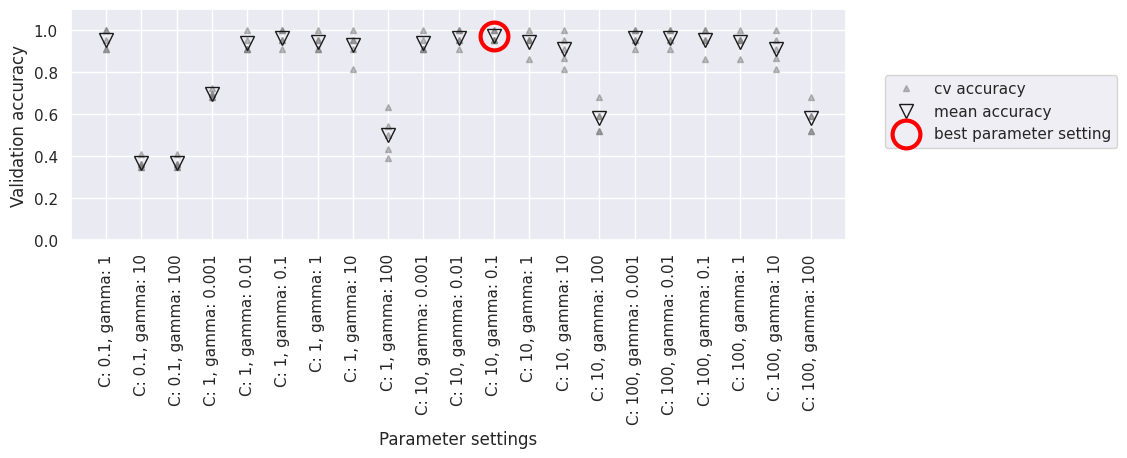

In [13]:
mglearn.plots.plot_cross_val_selection()

In [29]:
# @title
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.neighbors import KNeighborsClassifier

X, y = make_classification(n_samples=500, n_features=4, random_state=42)

# test 20%는 먼저 분리 (최종 평가 전용), 나머지 80%로 교차 검증
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# (p, k) 격자 탐색: 5개 fold 검증 정확도의 평균으로 비교
results = []
for p in (1, 2):
    for k in (1, 3, 5, 7, 9):
        scores = cross_val_score(KNeighborsClassifier(n_neighbors=k, p=p), X_train, y_train, cv=cv)
        results.append({"p": p, "k": k, "cv_mean": round(scores.mean(), 4), "cv_std": round(scores.std(), 4)})
        print(f"p={p} k={k} -> cv acc: {scores.mean():.4f} (±{scores.std():.4f})")

# CV 평균이 가장 높은 조합으로 train 전체를 재학습해 test 평가
best = max(results, key=lambda r: r["cv_mean"])
final = KNeighborsClassifier(n_neighbors=best["k"], p=best["p"]).fit(X_train, y_train)
best["test_acc"] = round(final.score(X_test, y_test), 4)

print(f"\n최적: p={best['p']}, k={best['k']} | test acc: {best['test_acc']:.4f}")
print(*results, sep="\n")

p=1 k=1 -> cv acc: 0.9400 (±0.0122)
p=1 k=3 -> cv acc: 0.9450 (±0.0187)
p=1 k=5 -> cv acc: 0.9450 (±0.0170)
p=1 k=7 -> cv acc: 0.9400 (±0.0215)
p=1 k=9 -> cv acc: 0.9350 (±0.0215)
p=2 k=1 -> cv acc: 0.9400 (±0.0122)
p=2 k=3 -> cv acc: 0.9475 (±0.0184)
p=2 k=5 -> cv acc: 0.9450 (±0.0232)
p=2 k=7 -> cv acc: 0.9400 (±0.0184)
p=2 k=9 -> cv acc: 0.9400 (±0.0146)

최적: p=2, k=3 | test acc: 0.9500
{'p': 1, 'k': 1, 'cv_mean': np.float64(0.94), 'cv_std': np.float64(0.0122)}
{'p': 1, 'k': 3, 'cv_mean': np.float64(0.945), 'cv_std': np.float64(0.0187)}
{'p': 1, 'k': 5, 'cv_mean': np.float64(0.945), 'cv_std': np.float64(0.017)}
{'p': 1, 'k': 7, 'cv_mean': np.float64(0.94), 'cv_std': np.float64(0.0215)}
{'p': 1, 'k': 9, 'cv_mean': np.float64(0.935), 'cv_std': np.float64(0.0215)}
{'p': 2, 'k': 1, 'cv_mean': np.float64(0.94), 'cv_std': np.float64(0.0122)}
{'p': 2, 'k': 3, 'cv_mean': np.float64(0.9475), 'cv_std': np.float64(0.0184), 'test_acc': 0.95}
{'p': 2, 'k': 5, 'cv_mean': np.float64(0.945), 'cv_st

In [30]:
# @title **1. GridSearchCV (모든 조합을 전부 탐색)**
from sklearn.model_selection import  GridSearchCV

X, y = make_classification(n_samples=500, n_features=4, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

param_grid = {"n_neighbors": [1, 3, 5, 7, 9], "p": [1, 2]}
grid = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5).fit(X_train, y_train)

print("최적 조합:", grid.best_params_)
print(f"CV acc: {grid.best_score_:.4f} | test acc: {grid.score(X_test, y_test):.4f}")

최적 조합: {'n_neighbors': 3, 'p': 2}
CV acc: 0.9525 | test acc: 0.9500


In [35]:
# @title **2. RandomizedSearchCV (무작위로 n_iter개만 탐색)**
from scipy.stats import randint
from sklearn.model_selection import RandomizedSearchCV

param_dist = {"n_neighbors": randint(1, 30), "p": [1, 2]}
rand = RandomizedSearchCV(
    KNeighborsClassifier(), param_dist, n_iter=10, cv=5, random_state=42
).fit(X_train, y_train)

print("최적 조합:", rand.best_params_)
print(f"CV acc: {rand.best_score_:.4f} | test acc: {rand.score(X_test, y_test):.4f}")

최적 조합: {'n_neighbors': 7, 'p': 2}
CV acc: 0.9475 | test acc: 0.9300


### **2.6 Conclusion**
`Age` and `Fare` features are binned. Binning helped dealing with outliers and it revealed some homogeneous groups in those features. `Family_Size` is created by adding `Parch` and `SibSp` features and **1**. `Ticket_Frequency` is created by counting the occurence of `Ticket` values.

`Name` feature is very useful. First, `Title` and `Is_Married` features are created from the title prefix in the names. Second, `Family_Survival_Rate` and `Family_Survival_Rate_NA`  features are created by target encoding the surname of the passengers. `Ticket_Survival_Rate` is created by target encoding the `Ticket` feature. `Survival_Rate` feature is created by averaging the `Family_Survival_Rate` and `Ticket_Survival_Rate` features.

Finally, the non-numeric type features are label encoded and categorical features are one-hot encoded. Created **5** new features (`Family_Size`, `Title`, `Is_Married`, `Survival_Rate` and `Survival_Rate_NA`) and dropped the useless features after encoding.

## **3. Model**

In [10]:
# @title **1. 범주형 변수 인코딩 및 데이터 스케일링**

### **3.1. K-nearest neighbor**


`StratifiedKFold` is used for stratifying the target variable. The folds are made by preserving the percentage of samples for each class in target variable (`Survived`).

### **3.2 Feature Importance**

### **3.3 ROC Curve**

### **3.4 Submission**

In [ ]:
class_survived = [col for col in probs.columns if col.endswith('Prob_1')]
probs['1'] = probs[class_survived].sum(axis=1) / N
probs['0'] = probs.drop(columns=class_survived).sum(axis=1) / N
probs['pred'] = 0
pos = probs[probs['1'] >= 0.5].index
probs.loc[pos, 'pred'] = 1

y_pred = probs['pred'].astype(int)

# df_test에서 직접 PassengerId를 가져오는 대신,
# 원본 df_all 데이터에서 test 세트 영역(index 891 이후)의 PassengerId를 복원하여 사용합니다.
original_test_passenger_ids = df_all.loc[891:, 'PassengerId']

submission_df = pd.DataFrame(columns=['PassengerId', 'Survived'])
submission_df['PassengerId'] = original_test_passenger_ids.values
submission_df['Survived'] = y_pred.values
submission_df.to_csv('submissions.csv', header=True, index=False)
submission_df.head(10)

,PassengerId,Survived
0,892,0
1,893,1
2,894,0
3,895,0
4,896,1
5,897,0
6,898,1
7,899,0
8,900,1
9,901,0


### **Optuna 하이퍼파라미터 튜닝 및 최적 모델 선택**
<font color='orange'> - **데이터 누수 방지: 전처리(preprocessor)를 파이프라인 안에 넣어서 CV의 fold마다 train 구간에서만 fit합니다. 그래서 앞 셀의 X_train_t가 아니라 변환 전의 X_train을 넣습니다.**
- 평가 기준: scoring='f1'로 5-fold 층화 CV의 평균 F1을 최대화하고 모델 간 비교도 이 값으로 합니다.
- 탐색 규모: 모델당 N_TRIALS = 30입니다. 시간이 부족하면 줄이고, 더 정밀하게 찾으려면 50~100으로 늘리세요.
- 재현성: SEED를 고정했습니다.
- FixedTrial: 저장된 최적 파라미터로 모델을 그대로 다시 만들기 위해 사용했습니다.
- 더 넓힐 때: XGBoost, LightGBM 같은 모델은 scikit-learn API(XGBClassifier 등)로 build_model에 같은 방식으로 추가할 수 있습니다.

In [ ]:
# @title **Optuna 하이퍼파라미터 튜닝 및 최적 모델 선택 (F1 기준)**

LogisticRegression   F1 = 0.7700
KNN                  F1 = 0.7708
SVC                  F1 = 0.7650
DecisionTree         F1 = 0.7658
RandomForest         F1 = 0.7744
ExtraTrees           F1 = 0.7714
GradientBoosting     F1 = 0.7820


,Model,Best_F1,Best_Params
0,GradientBoosting,0.782008,"{'n_estimators': 156, 'learning_rate': 0.01715..."
1,RandomForest,0.774384,"{'n_estimators': 433, 'max_depth': 6, 'min_sam..."
2,ExtraTrees,0.771445,"{'n_estimators': 433, 'max_depth': 6, 'min_sam..."
3,KNN,0.770836,"{'n_neighbors': 19, 'weights': 'uniform', 'p': 1}"
4,LogisticRegression,0.769994,{'C': 27.857747525323326}
5,DecisionTree,0.765785,"{'max_depth': 6, 'min_samples_split': 16, 'min..."
6,SVC,0.765031,"{'C': 0.06919094313572391, 'kernel': 'linear',..."



최고 모델: GradientBoosting (CV F1 = 0.7820)
최적 파라미터: {'n_estimators': 156, 'learning_rate': 0.017155648487123972, 'max_depth': 3, 'subsample': 0.7951143335383809}
